In [44]:
import librosa
import pandas as pd 
import numpy as np
import IPython.display as ipd
import matplotlib.pyplot as plt
import librosa.display
import sklearn.metrics as skm
import sklearn.model_selection as skms
from mutagen.mp3 import MP3
import os
from openpyxl import Workbook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.datasets import load_iris
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [20]:
import librosa

y , sr = librosa.load('y2mate.com - Lemon.mp3') # librosa.load() : 오디오 파일을 로드한다.

print(y)
print(len(y))
print('Sampling rate (Hz): %d' %sr)
print('Audio length (seconds): %.2f' % (len(y) / sr)) #음악의 길이(초) = 음파의 길이/Sampling rate
# y(소리의 세기) 값이 숫자로 이루어짐 ,음악의 길이 = 음파길이/sr 

[0. 0. 0. ... 0. 0. 0.]
5647872
Sampling rate (Hz): 22050
Audio length (seconds): 256.14


In [21]:
import pandas as pd 
import numpy as np

In [22]:
import IPython.display as ipd
ipd.Audio(y, rate=sr)
#음악을 들어볼수 있는 기능

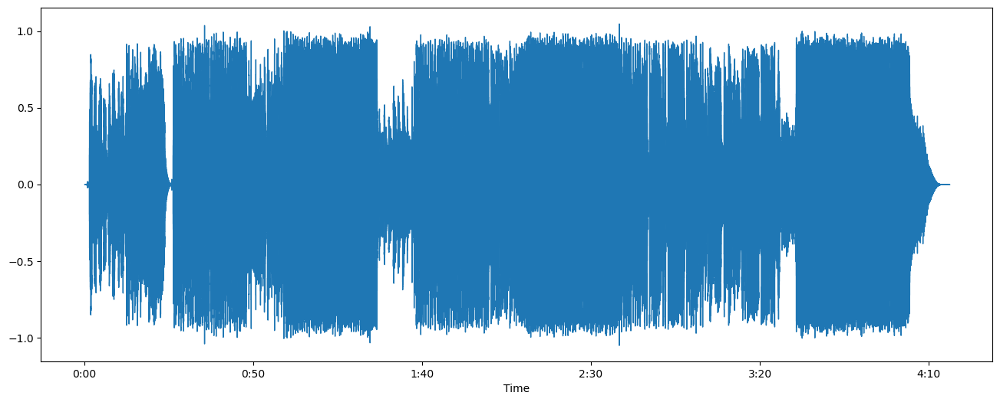

In [23]:
import matplotlib.pyplot as plt
import librosa.display

plt.figure(figsize=(16,6))
librosa.display.waveshow(y=y,sr=sr)
plt.show()

#2D 음파 그래프
#waveplot 은 이제 지원 암함 waveshow 사용할 것 

(1025, 11032)


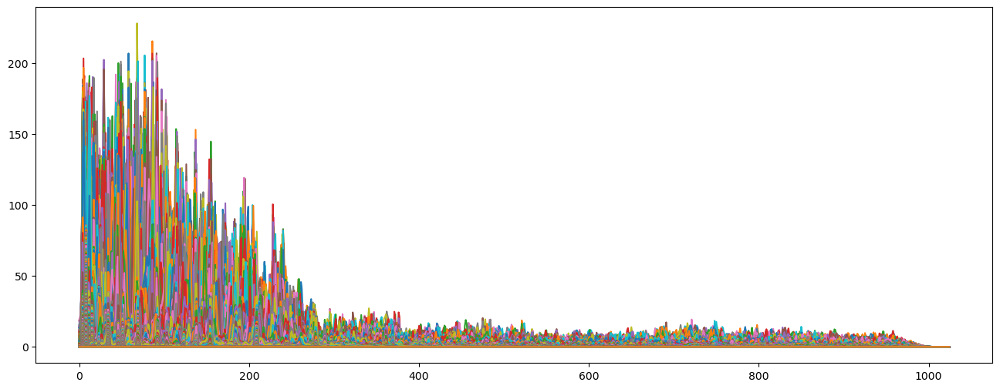

In [24]:
D = np.abs(librosa.stft(y, n_fft=2048, hop_length=512)) #n_fft : window size / 이 때, 음성의 길이를 얼마만큼으로 자를 것인가? 를 window라고 부른다.


print(D.shape)

plt.figure(figsize=(16,6))
plt.plot(D)
plt.show()

#푸리에 변환 
# 시간 영역 데이터를 주파수 영역으로 변경 time domain > frequency domain 변경시 얻는 정보가 많아져 분석에 용이
#y축 : 주파수(로그 스케일)
#color 축 : 데시벨(진폭)

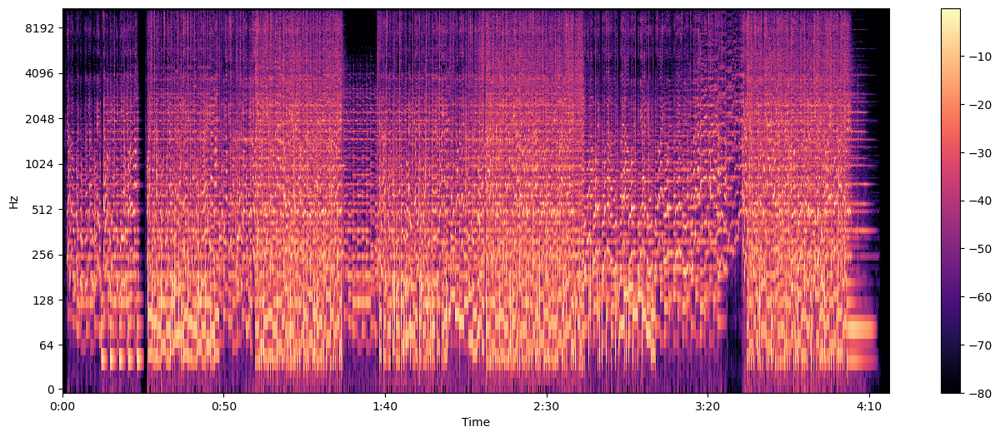

In [25]:
DB = librosa.amplitude_to_db(D, ref=np.max) #amplitude(진폭) -> DB(데시벨)로 바꿔라

plt.figure(figsize=(16,6))
librosa.display.specshow(DB,sr=sr, hop_length=512, x_axis='time', y_axis='log')
plt.colorbar()
plt.show()

#시간에 따른 시호 주파수의 스펙트럼 그래프 

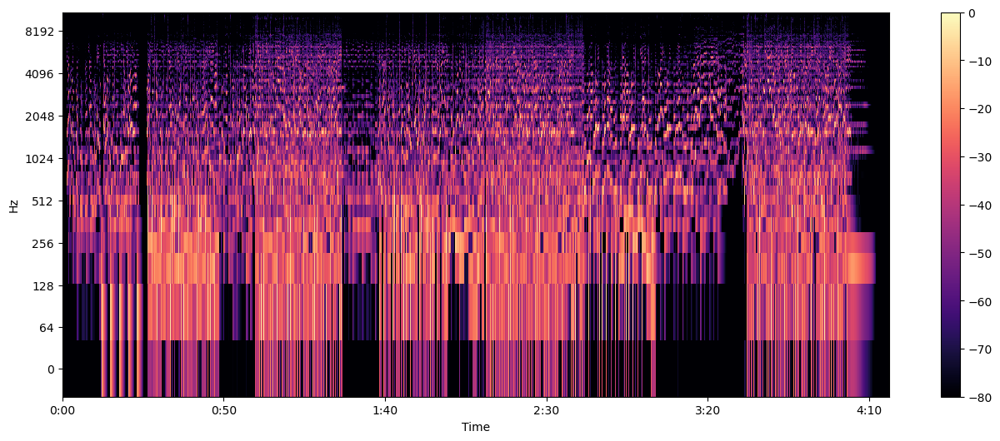

In [26]:
#MEl scale 화자 검증 가능 말하는 사람이 그 사람이 맞는지를 확인하는 기술 ex> siri

#보통 유사도를 정해놓고 들어오는 인풋 음성이 그 유사도보다 큰지 아닌지를 화자가 맞는지 판별하게 됨.

#음악이 인풋으로 들어오면 특정 구간에서 여러 feature들을 추출하고 , 분류하여 클래식인지 블루스인지 재즈인지 판별 할 수 있게 함

# https://m.blog.naver.com/PostView.naver?isHttpsRedirect=true&blogId=nm1lee&logNo=221915475247


S = librosa.feature.melspectrogram(y=y, sr=sr)
S_DB = librosa.amplitude_to_db(S, ref=np.max)

plt.figure(figsize=(16,6))
librosa.display.specshow(S_DB, sr=sr,hop_length=512, x_axis='time',y_axis='log')
plt.colorbar()
plt.show()

In [13]:
tempo , _ = librosa.beat.beat_track(y=y,sr=sr)     
print(tempo)

86.1328125


In [14]:
zero_crossings = librosa.zero_crossings(y, pad=False)

print(zero_crossings)
print(sum(zero_crossings)) # 음 <-> 양 이동한 횟수

#음파가 양에서 음으로 또는 음에서 양으로 바뀌는 비율

[False False False ... False False False]
511540


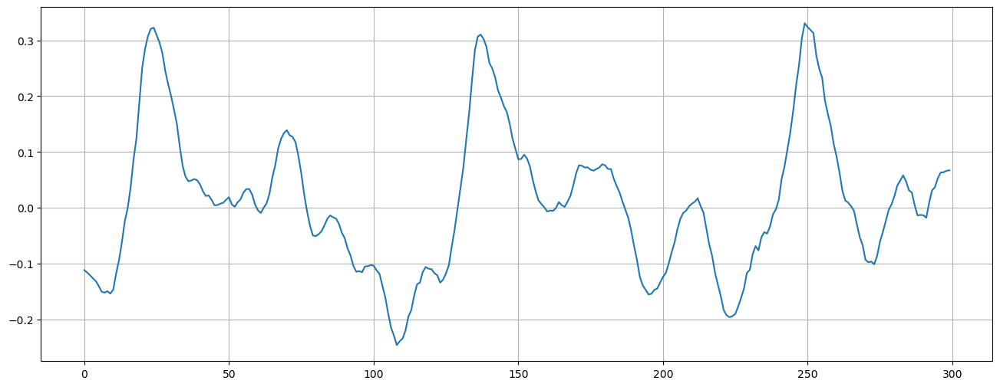

In [29]:
n0 = 50000
n1 = 50300
plt.figure(figsize=(16,6))
plt.plot(y[n0:n1])
plt.grid()
plt.show()

#구체적인 수치 확인 zero Crossing 은 0이 되는 선을 지나친 횟수

In [30]:
zero_crossings = librosa.zero_crossings(y[n0:n1], pad=False) #n0 ~ n1 사이 zero crossings 
print(sum(zero_crossings))

15


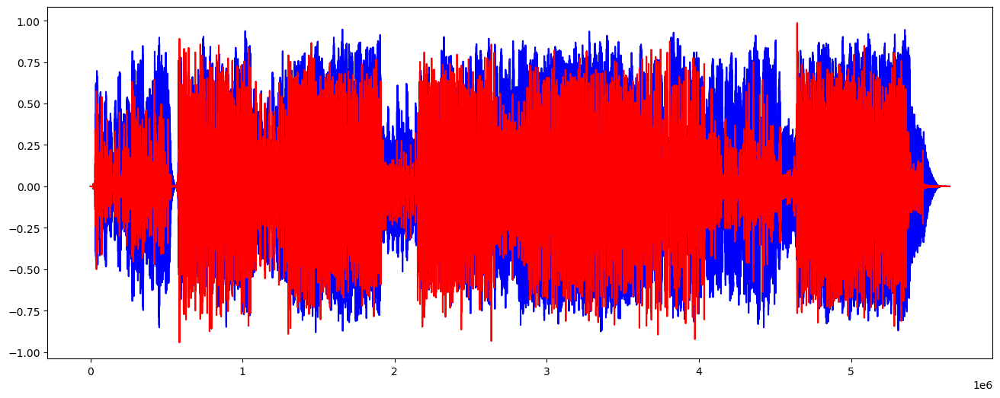

In [31]:
y_harm, y_perc = librosa.effects.hpss(y)

plt.figure(figsize=(16,6))
plt.plot(y_harm, color='b') #Harmonics : 사람의 귀로 구분할 수 없는 특징들(음악의 색깔)
plt.plot(y_perc, color='r') #Percussives: 리듬과 감정을 나타내는 충격파
plt.show()




AttributeError: module 'sklearn' has no attribute 'preprocessing'

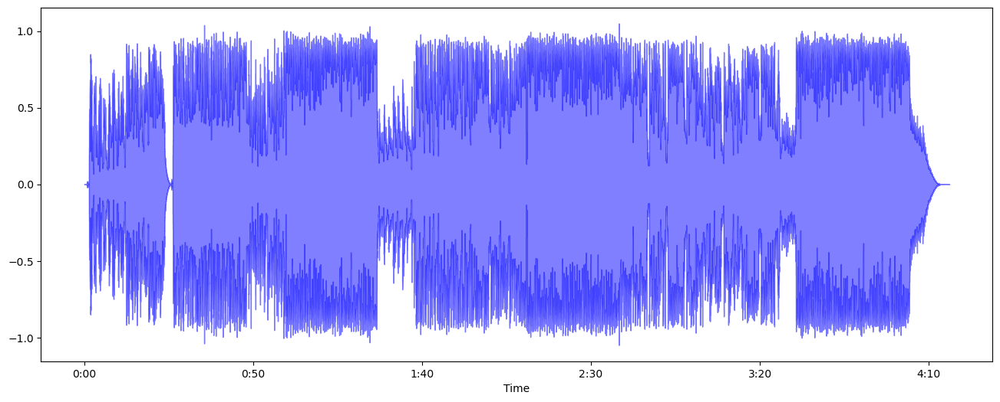

In [27]:
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)[0]

#Computing the time variable for visualization
frames = range(len(spectral_centroids))

# Converts frame counts to time (seconds)
t = librosa.frames_to_time(frames)

import sklearn
def normalize(x, axis=0):
  return sklearn.preprocessing.minmax_scale(x, axis=axis)    #sk.minmax_scale() : 최대 최소를 0 ~ 1 로 맞춰준다.

plt.figure(figsize=(16,6))
librosa.display.waveshow(y, sr=sr, alpha=0.5, color='b')
plt.plot(t, normalize(spectral_centroids), color='r')
plt.show()

#소리를 주파수로 표현했을 때, 주파수의 가중평균을 계산하여 수리의 무게 중심이 어딘지 알려주는 지표
#블루스 음악은 무게 중심이 가운데에 놓여있는 반면, 메탈음악은 노래의 마지막 부분에 무게 중심이 실림

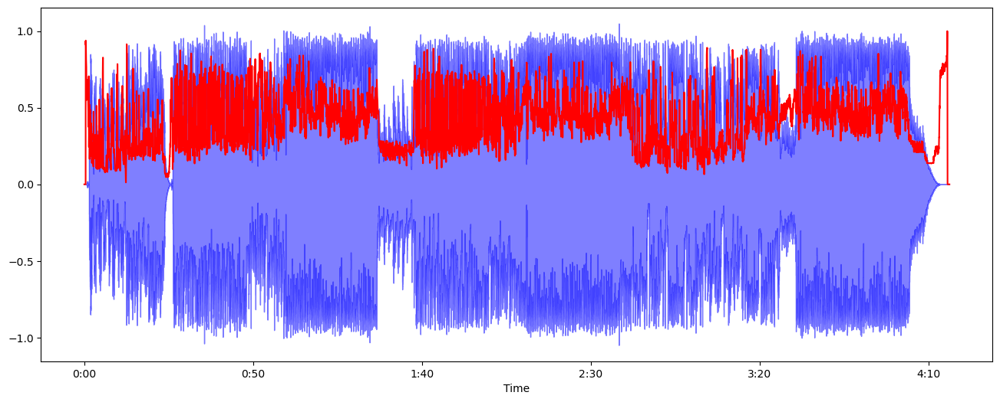

In [38]:
spectral_rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]

plt.figure(figsize=(16,6))
librosa.display.waveshow(y,sr=sr,alpha=0.5,color='b')
plt.plot(t, normalize(spectral_rolloff),color='r')
plt.show()

#신호 모양 측정 , 총 스펙트럴 에너지 중 낮은 주파수(85% 이하)에 얼마나 많이 집중되어 있는가를 표현

# Chroma Frequencies

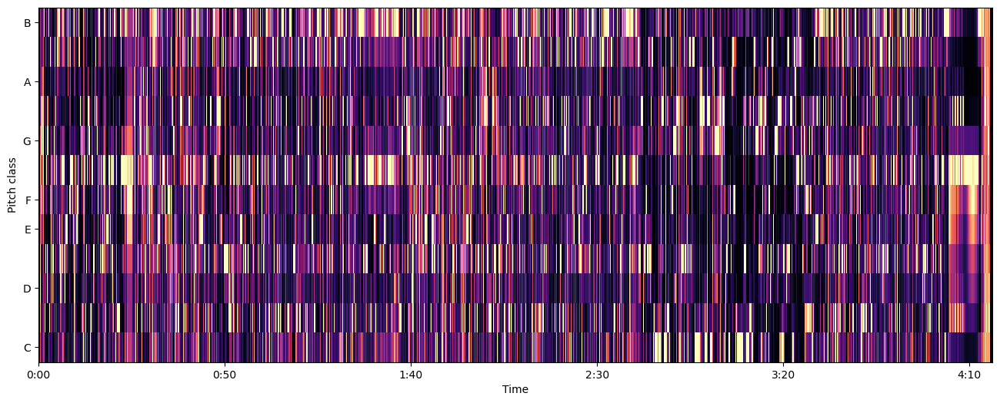

In [45]:
chromagram = librosa.feature.chroma_stft(y=y, sr=sr, hop_length=512)

plt.figure(figsize=(16,6))
librosa.display.specshow(chromagram,x_axis='time', y_axis='chroma', hop_length=512)
plt.show()

#음악의 흥미롭고 강렬한 표현
#크로마는 인간 청각이 옥타브 차이가 나는 주파수를 가진 두 음을 유사음으로 인지한다는 음악이론에 기반
#모든 스펙트럼을 12개의 Bin 으로 표현하고 12개의 Bin 은 옥타프에서 12개의 가지 다른 반응을 의미함.

mean: 0.54
var: 0.02


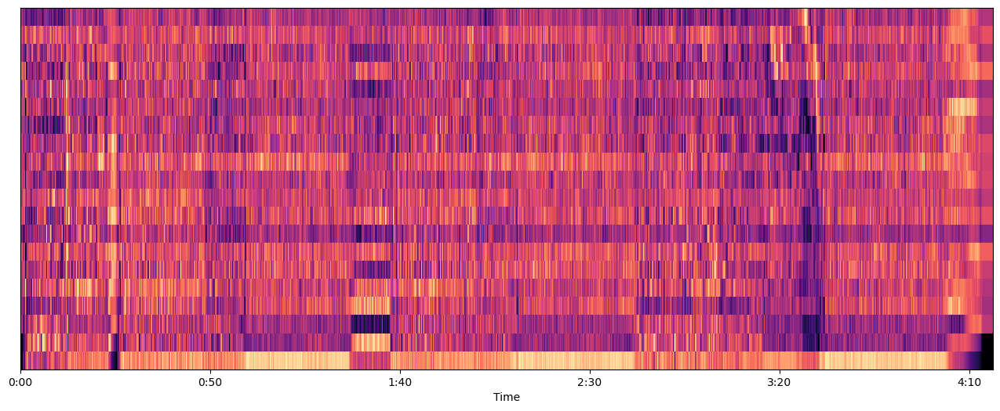

In [40]:
mfccs = librosa.feature.mfcc(y=y, sr=sr)
mfccs = normalize(mfccs,axis=1)

print('mean: %.2f' % mfccs.mean())
print('var: %.2f' % mfccs.var())

plt.figure(figsize=(16,6))
librosa.display.specshow(mfccs,sr=sr, x_axis='time')
plt.show()

# https://tech.kakaoenterprise.com//66

In [47]:
!pip install -q kaggle

In [56]:
!pip show kaggle

Name: kaggle
Version: 1.5.13
Summary: Kaggle API
Home-page: https://github.com/Kaggle/kaggle-api
Author: Kaggle
Author-email: support@kaggle.com
License: Apache 2.0
Location: c:\users\hoo\anaconda3\lib\site-packages
Requires: certifi, python-dateutil, python-slugify, requests, six, tqdm, urllib3
Required-by: 


In [57]:
df = pd.read_csv('features_3_sec.csv')

df.head()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues


In [58]:
X = df.drop(columns=['filename','length','label']) 
y = df['label'] #장르명

scaler = sklearn.preprocessing.MinMaxScaler()
np_scaled = scaler.fit_transform(X)

X = pd.DataFrame(np_scaled, columns=X.columns)

X.head()

,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
0,0.355399,0.716757,0.293133,0.107955,0.262173,0.034784,0.459205,0.094130,0.346153,0.083164,...,0.363613,0.056198,0.397172,0.066062,0.371828,0.055344,0.380831,0.026797,0.506746,0.047781
1,0.367322,0.670347,0.253040,0.044447,0.270969,0.018716,0.470831,0.052261,0.363722,0.051694,...,0.468596,0.092912,0.351681,0.074001,0.362068,0.076365,0.418452,0.082414,0.593029,0.065548
2,0.373159,0.728067,0.296753,0.141663,0.265293,0.023073,0.494051,0.059922,0.378215,0.060820,...,0.479681,0.096704,0.420979,0.050639,0.400536,0.067509,0.433742,0.043841,0.546264,0.036062
3,0.399349,0.677066,0.298024,0.075042,0.238427,0.023187,0.455246,0.066234,0.329587,0.070906,...,0.386258,0.067995,0.387474,0.050617,0.380430,0.050030,0.405824,0.041898,0.562204,0.034873
4,0.355668,0.689113,0.322308,0.052149,0.233460,0.016451,0.451651,0.047830,0.318453,0.046916,...,0.438567,0.042500,0.460314,0.083860,0.388590,0.076524,0.409019,0.020763,0.517913,0.031713


In [59]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train, y_test = train_test_split(X,y , test_size=0.2, random_state=2021)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(7992, 57) (7992,)
(1998, 57) (1998,)


In [70]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train = le.fit_transform(y_train)

In [71]:
from xgboost import XGBClassifier #xgboost 모델이 좋다길래 ..!!
from sklearn.metrics import accuracy_score

xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05) #1000개의 가지? epoch? , 0.05 학습률
xgb.fit(X_train, y_train) #학습

y_preds = xgb.predict(X_test) #검증

print('Accuracy: %.2f' % accuracy_score(y_test,y_preds))

Accuracy: 0.00


In [72]:
from sklearn.metrics import confusion_matrix, accuracy_score
y_pred = xgb.predict(X_test.values)
y_pred = le.inverse_transform(y_pred)
cm = confusion_matrix(y_test, y_pred)
print(cm)
accuracy_score(y_test, y_pred)

[[177   1   4   4   2   2   1   0   1   2]
 [  1 183   2   0   0   6   0   0   0   1]
 [  4   1 174   2   1   7   0   3   4   2]
 [  1   0   1 195   2   0   1   5   2   7]
 [  2   1   4   3 185   3   3   6   4   0]
 [  6   7   2   1   0 174   0   2   0   0]
 [  0   1   0   1   1   0 191   0   0   7]
 [  0   0   6   7   1   1   0 199   0   3]
 [  3   0   7   1   2   3   0   3 180   0]
 [  2   2   9   5   0   2   5   2   1 151]]


0.9054054054054054

In [85]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test,y_preds)

plt.figure(figsize=(16,9))
sns.heatmap(
    cm,
    annot=True,
    xticklabels=["blues","classical","country","disco","hiphop","jazz","metal","pop","reggae","rock"],
    yticklabels=["blues","classical","country","disco","hiphop","jazz","metal","pop","reggae","rock"]
)
plt.show()

# 왜 오류 뜨는지 모르겠음 ㄹㅇ

ValueError: Mix of label input types (string and number)

# 이건 다른거 종류 같은데 마찬가지로 유사도 나타내는 듯

In [78]:
import sklearn.metrics as skm
import sklearn.model_selection as skms

In [79]:
def results(model, X, validation=False):
    y_true = y_train
    if validation:
        X = X_validation[X.columns]
        y_true = y_validation
    y_prediction = model.predict(X)
    confusion_matrix = skm.confusion_matrix(y_true, y_prediction)
    cm_display = skm.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix)
    cm_display.plot()
    plt.show()
    print(skm.classification_report(y_true, y_prediction, digits=3))
    print(skm.precision_recall_fscore_support(y_true, y_prediction, average="macro"))
    print("=====================================================")

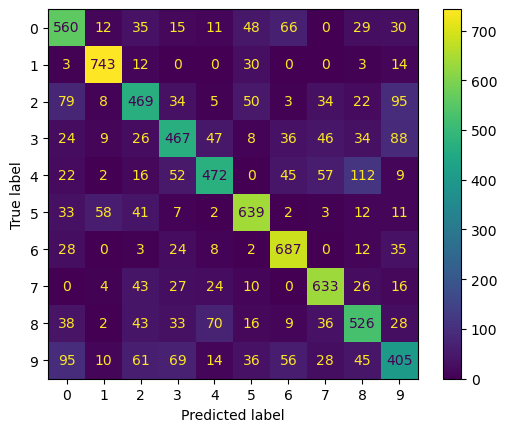

              precision    recall  f1-score   support

           0      0.635     0.695     0.664       806
           1      0.876     0.923     0.899       805
           2      0.626     0.587     0.606       799
           3      0.641     0.595     0.617       785
           4      0.723     0.600     0.656       787
           5      0.762     0.791     0.776       808
           6      0.760     0.860     0.807       799
           7      0.756     0.808     0.781       783
           8      0.641     0.657     0.649       801
           9      0.554     0.495     0.523       819

    accuracy                          0.701      7992
   macro avg      0.697     0.701     0.698      7992
weighted avg      0.697     0.701     0.697      7992

(0.6974136178873248, 0.7009684636475438, 0.6976705890851672, None)


NameError: name 'X_validation' is not defined

In [80]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=400)
lr.fit(X_train, y_train)
results(lr, X_train)
results(lr, X_train, validation=True)

## 여기선 부터 다시 시작

In [81]:
for feature, importance in zip(X_test.columns, xgb.feature_importances_):
  print('%s: %.2f' % (feature, importance))   #어떤 특징이 중요했는지 보여줌

chroma_stft_mean: 0.04
chroma_stft_var: 0.03
rms_mean: 0.02
rms_var: 0.03
spectral_centroid_mean: 0.02
spectral_centroid_var: 0.02
spectral_bandwidth_mean: 0.06
spectral_bandwidth_var: 0.01
rolloff_mean: 0.02
rolloff_var: 0.03
zero_crossing_rate_mean: 0.02
zero_crossing_rate_var: 0.01
harmony_mean: 0.02
harmony_var: 0.02
perceptr_mean: 0.02
perceptr_var: 0.08
tempo: 0.02
mfcc1_mean: 0.03
mfcc1_var: 0.04
mfcc2_mean: 0.01
mfcc2_var: 0.01
mfcc3_mean: 0.02
mfcc3_var: 0.02
mfcc4_mean: 0.04
mfcc4_var: 0.01
mfcc5_mean: 0.01
mfcc5_var: 0.02
mfcc6_mean: 0.02
mfcc6_var: 0.01
mfcc7_mean: 0.01
mfcc7_var: 0.02
mfcc8_mean: 0.01
mfcc8_var: 0.01
mfcc9_mean: 0.02
mfcc9_var: 0.01
mfcc10_mean: 0.01
mfcc10_var: 0.01
mfcc11_mean: 0.01
mfcc11_var: 0.01
mfcc12_mean: 0.02
mfcc12_var: 0.01
mfcc13_mean: 0.01
mfcc13_var: 0.01
mfcc14_mean: 0.01
mfcc14_var: 0.01
mfcc15_mean: 0.01
mfcc15_var: 0.01
mfcc16_mean: 0.01
mfcc16_var: 0.01
mfcc17_mean: 0.01
mfcc17_var: 0.01
mfcc18_mean: 0.01
mfcc18_var: 0.01
mfcc19_mean: 0

### 실제 간단한 분석

In [82]:
df_30 = pd.read_csv('features_30_sec.csv', index_col='filename')

labels = df_30[['label']]
df_30 = df_30.drop(columns=['length','label'])

df_30_scaled = sklearn.preprocessing.scale(df_30)  #평균 0 , 표준편차 1 

df_30 = pd.DataFrame(df_30_scaled, columns=df_30.columns)

df_30.head()

,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
0,-0.350137,0.312587,-0.010690,-0.061856,-0.583585,-0.848311,-0.456402,-0.531042,-0.486473,-0.661934,...,-0.086396,-0.246114,0.500462,-0.780265,-0.237040,-0.643177,0.006723,-0.300597,0.604064,-0.512988
1,-0.462482,1.117572,-0.532852,-0.186821,-0.938516,-0.234194,-0.386852,0.796252,-0.648681,0.795823,...,-0.048102,-0.159175,0.711371,-0.069304,-0.054982,-0.453456,0.544806,-0.407087,0.424127,-0.538421
2,-0.184225,-0.137701,0.679978,-0.084093,-0.906885,-0.781694,-0.940663,-0.630916,-0.971592,-0.744406,...,0.284825,-0.596243,-0.827516,-0.448091,-0.600983,-0.329519,-0.295934,-0.527297,-0.296189,-0.874954
3,0.319639,0.990659,0.154810,0.907029,-1.581429,-0.712095,-1.228256,0.304565,-1.516390,-0.246530,...,-0.080249,-0.482843,0.142153,-0.371370,0.033427,-0.767591,0.455409,-0.779744,-0.602881,-0.844508
4,-0.859077,0.194163,-0.600165,-0.205909,-0.512542,-0.315178,-0.939770,-0.504463,-0.630107,-0.190517,...,-1.238616,0.751318,-0.327220,0.377620,-0.368375,-0.293696,-0.553016,-0.089383,-2.766009,-0.330287


In [83]:
from sklearn.metrics.pairwise import cosine_similarity
similarity = cosine_similarity(df_30)   #벡터의 유사도 , 즉 벡터간의 각도를 통해 추정 cos0 =1 이므로 1에 가까울 수록 유사 / cos180 = -1 이므로 -1에 가까울 수록 다르다.

sim_df = pd.DataFrame(similarity, index=labels.index, columns=labels.index)

sim_df.head()

filename,blues.00000.wav,blues.00001.wav,blues.00002.wav,blues.00003.wav,blues.00004.wav,blues.00005.wav,blues.00006.wav,blues.00007.wav,blues.00008.wav,blues.00009.wav,...,rock.00090.wav,rock.00091.wav,rock.00092.wav,rock.00093.wav,rock.00094.wav,rock.00095.wav,rock.00096.wav,rock.00097.wav,rock.00098.wav,rock.00099.wav
filename,,,,,,,,,,,,,,,,,,,,,
blues.00000.wav,1.000000,0.049231,0.589618,0.284862,0.025561,-0.346688,-0.219483,-0.167626,0.641877,-0.097889,...,-0.082829,0.546169,0.578558,0.662590,0.571629,0.610942,0.640835,0.496294,0.284958,0.304098
blues.00001.wav,0.049231,1.000000,-0.096834,0.520903,0.080749,0.307856,0.318286,0.415258,0.120649,0.404168,...,-0.098111,-0.325126,-0.370792,-0.191698,-0.330834,-0.077301,-0.222119,-0.302573,0.499562,0.311723
blues.00002.wav,0.589618,-0.096834,1.000000,0.210411,0.400266,-0.082019,-0.028061,0.104446,0.468113,-0.132532,...,-0.032408,0.561074,0.590779,0.583293,0.514537,0.495707,0.566837,0.589983,0.216378,0.321069
blues.00003.wav,0.284862,0.520903,0.210411,1.000000,0.126437,0.134796,0.300746,0.324566,0.352758,0.295184,...,-0.320107,-0.206516,-0.151132,0.041986,-0.172515,-0.000287,0.020515,-0.107821,0.502279,0.183210
blues.00004.wav,0.025561,0.080749,0.400266,0.126437,1.000000,0.556066,0.482195,0.623455,0.029703,0.471657,...,0.087605,0.017366,0.138035,0.104684,-0.034594,0.063454,0.063546,0.172944,0.153192,0.061785


In [84]:
def find_similar_songs(name, n=5):
  series = sim_df[name].sort_values(ascending=False)

  series = series.drop(name)

  return series.head(n).to_frame()

find_similar_songs('rock.00000.wav')

# rock.0000 와 유사한 상위 5개의 곡이 추천됨

,rock.00000.wav
filename,
rock.00079.wav,0.681819
rock.00026.wav,0.677842
country.00070.wav,0.675324
rock.00064.wav,0.662020
rock.00096.wav,0.654814


# -----------------------------------------------------------------------------------------------------#

In [4]:
from mutagen.mp3 import MP3
import os
from openpyxl import Workbook

# Directory containing audio files
directory = "MUSIC"

# Create new Excel workbook
workbook = Workbook()
worksheet = workbook.active

# Loop through all files in directory
for row, filename in enumerate(os.listdir(directory), start=1):
    if filename.endswith(".mp3"):
        # Construct full path of file
        filepath = os.path.join(directory, filename)
        # Read audio length using mutagen
        audio = MP3(filepath)
        length_in_secs = audio.info.length
        # Write results to Excel
        worksheet.cell(row=row, column=1, value=filename)
        worksheet.cell(row=row, column=2, value=length_in_secs)

# Save Excel workbook
workbook.save("music_lengths.xlsx")

In [61]:
y, sr = librosa.load('blues.00001.wav')

# Calculate chromagram
chromagram = librosa.feature.chroma_stft(y=y, sr=sr, hop_length=512)

# Calculate mean of chromagram
chromagram_mean = np.mean(chromagram, axis=1)

# Convert mean chromagram to pandas DataFrame
df = pd.DataFrame(data=chromagram_mean.reshape(1, -1), columns=['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B'])

# Export DataFrame to Excel file
df.to_excel('chromagram_mean.xlsx', index=False)

In [59]:
# 음악 파일이 있는 폴더 경로
audio_dir = 'MUSIC'

# 폴더 내 모든 mp3 파일 가져오기
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.mp3')]

# chroma_stft_mean 추출
chroma_stft_mean_list = []
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    chroma_stft = librosa.feature.chroma_stft(y=y, sr=sr)
    chroma_stft_mean = chroma_stft.mean(axis=1)
    chroma_stft_mean_list.append(chroma_stft_mean)

# chroma_stft_mean 값들의 평균 계산
chroma_stft_mean_avg_list = []
for chroma_stft_mean in chroma_stft_mean_list:
    chroma_stft_mean_avg = np.mean(chroma_stft_mean)
    chroma_stft_mean_avg_list.append(chroma_stft_mean_avg)

# 결과값 데이터프레임으로 변환
df = pd.DataFrame({'audio_file': audio_files, 'chroma_stft_mean_avg': chroma_stft_mean_avg_list})

# 엑셀 파일로 저장
df.to_excel('chroma_stft_mean_avg.xlsx', index=False)

In [65]:
# 음악 파일이 있는 폴더 경로
audio_dir = 'MUSIC'

# 폴더 내 모든 mp3 파일 가져오기
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.mp3')]

# chroma_stft_var 추출
chroma_stft_var_list = []
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    chroma_stft = librosa.feature.chroma_stft(y=y, sr=sr)
    chroma_stft_var = chroma_stft.var(axis=1)
    chroma_stft_var_list.append(chroma_stft_var)

# chroma_stft_var 값들의 평균 계산
chroma_stft_var_avg_list = []
for chroma_stft_var in chroma_stft_var_list:
    chroma_stft_var_avg = np.mean(chroma_stft_var)
    chroma_stft_var_avg_list.append(chroma_stft_var_avg)

# 결과값 데이터프레임으로 변환
df = pd.DataFrame({'audio_file': audio_files, 'chroma_stft_var_avg': chroma_stft_var_avg_list})

# 엑셀 파일로 저장
df.to_excel('chroma_stft_var_avg.xlsx', index=False)

#### ram 기계적으로 소리의 에너지값을 평균낸것

In [66]:
# 음악 파일이 있는 폴더 경로
audio_dir = 'MUSIC'

# 폴더 내 모든 mp3 파일 가져오기
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.mp3')]

# rms_mean 추출
rms_mean_list = []
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    rms = librosa.feature.rms(y=y)
    rms_mean = np.mean(rms)
    rms_mean_list.append(rms_mean)

# 결과값 데이터프레임으로 변환
df = pd.DataFrame({'audio_file': audio_files, 'rms_mean': rms_mean_list})

# 엑셀 파일로 저장
df.to_excel('rms_mean.xlsx', index=False)

In [68]:
# 음악 파일이 있는 폴더 경로
audio_dir = 'MUSIC'

# 폴더 내 모든 mp3 파일 가져오기
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.mp3')]

# rms_var 추출
rms_var_list = []
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    rms = librosa.feature.rms(y=y)
    rms_var = np.var(rms)
    rms_var_list.append(rms_var)

# 결과값 데이터프레임으로 변환
df = pd.DataFrame({'audio_file': audio_files, 'rms_var': rms_var_list})

# 엑셀 파일로 저장
df.to_excel('rms_var.xlsx', index=False)

### 무게 중심 

In [69]:
# 음악 파일이 있는 폴더 경로
audio_dir = 'blues'

# 폴더 내 모든 mp3 파일 가져오기
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.wav')]

# spectral_centroid_mean 추출
spec_cent_mean_list = []
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr)
    spec_cent_mean = np.mean(spec_cent)
    spec_cent_mean_list.append(spec_cent_mean)

# 결과값 데이터프레임으로 변환
df = pd.DataFrame({'audio_file': audio_files, 'spec_cent_mean': spec_cent_mean_list})

# 엑셀 파일로 저장
df.to_excel('spec_cent_mean.xlsx', index=False)

In [ ]:
# 음악 파일이 있는 폴더 경로
audio_dir = 'audio_folder'

# 폴더 내 모든 mp3 파일 가져오기
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.mp3')]

# spectral_centroid_var 추출
spec_cent_var_list = []
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr)
    spec_cent_var = np.var(spec_cent)
    spec_cent_var_list.append(spec_cent_var)

# 결과값 데이터프레임으로 변환
df = pd.DataFrame({'audio_file': audio_files, 'spec_cent_var': spec_cent_var_list})

# 엑셀 파일로 저장
df.to_excel('spec_cent_var.xlsx', index=False)

##### 스펙트럼 중심은 신호의 "평균" 주파수를 측정한 반면 스펙트럼 대역폭은 신호에 존재하는 주파수 범위를 측정한 것

In [71]:
# Audio folder path
audio_dir = 'blues'

# Get all the mp3 files in the folder
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.wav')]

# Initialize lists to store the results
spec_bw_mean_list = []
spec_bw_var_list = []

# Loop through each file and extract the features
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    spec_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    spec_bw_mean = np.mean(spec_bw)
    spec_bw_var = np.var(spec_bw)
    spec_bw_mean_list.append(spec_bw_mean)
    spec_bw_var_list.append(spec_bw_var)

# Create a data frame to store the results
df = pd.DataFrame({'audio_file': audio_files, 'spec_bw_mean': spec_bw_mean_list, 'spec_bw_var': spec_bw_var_list})

# Calculate the mean values
spec_bw_mean_avg = df['spec_bw_mean'].mean()
spec_bw_var_avg = df['spec_bw_var'].mean()

# Print the mean values
print("Average spectral bandwidth mean:", spec_bw_mean_avg)
print("Average spectral bandwidth variance:", spec_bw_var_avg)

# Save the results to an Excel file
df.to_excel('spectral_bandwidth.xlsx', index=False)

Average spectral bandwidth mean: 2005.0640180218209
Average spectral bandwidth variance: 137959.88593547643


#### roleoff 신호 모양 측정 , 총 스펙트럴 에너지 중 낮은 주파수(85% 이하)에 얼마나 많이 집중되어 있는가를 표현

In [78]:
# directory containing music files
dir_path = 'blues'

# create an empty list to store the rolloff values for each file
rolloff_values = []

# loop through each file in the directory
for filename in os.listdir(dir_path):
    if filename.endswith('.mp3') or filename.endswith('.wav'): 
        # load audio file
        audio_path = os.path.join(dir_path, filename)
        y, sr = librosa.load(audio_path, sr=None)
        
        # calculate rolloff values
        rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
        rolloff_mean = rolloff.mean()
        rolloff_var = rolloff.var()
        
        # add rolloff values to list
        rolloff_values.append((filename, rolloff_mean, rolloff_var))

# calculate average rolloff values
rolloff_means = [x[1] for x in rolloff_values]
rolloff_variances = [x[2] for x in rolloff_values]
mean_rolloff_mean = sum(rolloff_means) / len(rolloff_means)
mean_rolloff_var = sum(rolloff_variances) / len(rolloff_variances)

# create an Excel workbook
workbook = openpyxl.Workbook()
sheet = workbook.active
sheet.title = 'Rolloff values'

# write rolloff values to Excel sheet
sheet.cell(row=1, column=1, value='Filename')
sheet.cell(row=1, column=2, value='Rolloff Mean')
sheet.cell(row=1, column=3, value='Rolloff Variance')
for i, values in enumerate(rolloff_values, start=2):
    sheet.cell(row=i, column=1, value=values[0])
    sheet.cell(row=i, column=2, value=values[1])
    sheet.cell(row=i, column=3, value=values[2])

# write average rolloff values to Excel sheet
sheet.cell(row=len(rolloff_values)+2, column=1, value='Average')
sheet.cell(row=len(rolloff_values)+2, column=2, value=mean_rolloff_mean)
sheet.cell(row=len(rolloff_values)+2, column=3, value=mean_rolloff_var)

# save Excel workbook
workbook.save('rolloff_values.xlsx')

### harmonic_percussive_features

In [90]:
# Folder path with music files
audio_dir = 'blues'

# Get all mp3 files in a folder
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.wav')]

# extract harmonic and percussive components and their means and variances
harmony_mean_list = []
harmony_var_list = []
percussive_mean_list = []
percussive_var_list = []
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    y_harmonic, y_percussive = librosa.effects.hpss(y)
    harmony_mean = np.mean(y_harmonic)
    harmony_var = np.var(y_harmonic)
    percussive_mean = np.mean(y_percussive)
    percussive_var = np.var(y_percussive)
    harmony_mean_list.append(harmony_mean)
    harmony_var_list.append(harmony_var)
    percussive_mean_list.append(percussive_mean)
    percussive_var_list.append(percussive_var)

# Convert the result into a data frame
df = pd.DataFrame({
    'audio_file': audio_files,
    'harmony_mean': harmony_mean_list,
    'harmony_var': harmony_var_list,
    'percussive_mean': percussive_mean_list,
    'percussive_var': percussive_var_list
})

# Save as excel file
df.to_excel('harmonic_percussive_features.xlsx', index=False)

#### zero crossing 

In [87]:
audio_dir = 'blues'

# Get all mp3 files in a folder
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.wav')]

# extract zero_crossing_rate_mean and zero_crossing_rate_var
zcr_mean_list = []
zcr_var_list = []
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    zcr = librosa.feature.zero_crossing_rate(y=y)
    zcr_mean = np.mean(zcr)
    zcr_var = np.var(zcr)
    zcr_mean_list.append(zcr_mean)
    zcr_var_list.append(zcr_var)

# Convert the result into a data frame
df = pd.DataFrame({
    'audio_file': audio_files,
    'zero_crossing_rate_mean': zcr_mean_list,
    'zero_crossing_rate_var': zcr_var_list
})

# Save as excel file
df.to_excel('zero_crossing_rate_stats.xlsx', index=False)

### tempo 

In [94]:
# Folder path with music files
audio_dir = 'blues'

# Get all mp3 files in a folder
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.wav')]

# extract tempo
tempo_list = []
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    tempo_list.append(tempo)

# Convert the result into a data frame
df = pd.DataFrame({'audio_file': audio_files, 'tempo': tempo_list})

# Save as excel file
df.to_excel('tempo.xlsx', index=False)


In [11]:
# Folder path with music files
audio_dir = 'MUSIC'

# Get all mp3 files in a folder
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.mp3')]

# Initialize lists to store feature values
chroma_stft_mean_list = []
chroma_stft_var_list = []
rms_mean_list = []
rms_var_list = []
spec_cent_mean_list = []
spec_cent_var_list = []
spec_bw_mean_list = []
spec_bw_var_list = []
rolloff_mean_list = []
rolloff_var_list = []
zcr_mean_list = []
zcr_var_list = []
harmony_mean_list = []
harmony_var_list = []
perceptr_mean_list = []
perceptr_var_list = []
tempo_list = []
music_lengths = []

# Extract features for each audio file
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    
    # Chroma feature
    chroma_stft = librosa.feature.chroma_stft(y=y, sr=sr)
    chroma_stft_mean = chroma_stft.mean(axis=1)
    chroma_stft_var = chroma_stft.var(axis=1)
    chroma_stft_mean_list.append(chroma_stft_mean)
    chroma_stft_var_list.append(chroma_stft_var)
    
    # Calculate mean of chroma_stft_mean_list
    chroma_stft_mean_list_mean = np.mean(chroma_stft_mean_list, axis=1)

    # Calculate mean of chroma_stft_var_list
    chroma_stft_var_list_mean = np.mean(chroma_stft_var_list, axis=1)
    
    
    # RMS feature
    rms = librosa.feature.rms(y=y)
    rms_mean = np.mean(rms)
    rms_var = np.var(rms)
    rms_mean_list.append(rms_mean)
    rms_var_list.append(rms_var)
    
    # Spectral centroid feature
    spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr)
    spec_cent_mean = np.mean(spec_cent)
    spec_cent_var = np.var(spec_cent)
    spec_cent_mean_list.append(spec_cent_mean)
    spec_cent_var_list.append(spec_cent_var)
    
    # Spectral bandwidth feature
    spec_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    spec_bw_mean = np.mean(spec_bw)
    spec_bw_var = np.var(spec_bw)
    spec_bw_mean_list.append(spec_bw_mean)
    spec_bw_var_list.append(spec_bw_var)
    
    # Spectral rolloff feature
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    rolloff_mean = np.mean(rolloff)
    rolloff_var = np.var(rolloff)
    rolloff_mean_list.append(rolloff_mean)
    rolloff_var_list.append(rolloff_var)
    
    # Zero-crossing rate feature
    zcr = librosa.feature.zero_crossing_rate(y=y)
    zcr_mean = np.mean(zcr)
    zcr_var = np.var(zcr)
    zcr_mean_list.append(zcr_mean)
    zcr_var_list.append(zcr_var)
    
    # Harmonic and percussive features
    y_harmonic, y_percussive = librosa.effects.hpss(y)
    harmony = librosa.effects.harmonic(y)
    harmony_mean = np.mean(harmony)
    harmony_var = np.var(harmony)
    harmony_mean_list.append(harmony_mean)
    harmony_var_list.append(harmony_var)
    perceptr = librosa.effects.percussive(y)
    perceptr_mean = np.mean(perceptr)
    perceptr_var = np.var(perceptr)
    perceptr_mean_list.append(perceptr_mean)
    perceptr_var_list.append(perceptr_var)
    
    # Tempo feature
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    tempo_list.append(tempo)
    
    # Music length feature
    music_length = librosa.get_duration(y=y, sr=sr)
    music_lengths.append(music_length)
    
df = pd.DataFrame({'audio_file': audio_files, 'music_length' : music_length, 
'chroma_stft_mean': chroma_stft_mean_list_mean, 'chroma_stft_var': chroma_stft_var_list_mean,
'rms_mean': rms_mean_list, 'rms_var': rms_var_list,
'spec_cent_mean': spec_cent_mean_list, 'spec_cent_var': spec_cent_var_list,
'spec_bw_mean': spec_bw_mean_list, 'spec_bw_var': spec_bw_var_list,
'rolloff_mean': rolloff_mean_list, 'rolloff_var': rolloff_var_list,
'zcr_mean': zcr_mean_list, 'zcr_var': zcr_var_list,
'harmony_mean': harmony_mean_list, 'harmony_var': harmony_var_list,
'perceptr_mean': perceptr_mean_list, 'perceptr_var': perceptr_var_list,
'tempo': tempo_list})


df.to_excel('데이터 정리.xlsx', index=False)

In [12]:
import os
# Folder path with music files
audio_dir = '55'

# Get all mp3 files in a folder
audio_files = [file for file in os.listdir(audio_dir) if file.endswith('.m4a') or file.endswith('.flac')]

# Initialize lists to store feature values
chroma_stft_mean_list = []
chroma_stft_var_list = []
rms_mean_list = []
rms_var_list = []
spec_cent_mean_list = []
spec_cent_var_list = []
spec_bw_mean_list = []
spec_bw_var_list = []
rolloff_mean_list = []
rolloff_var_list = []
zcr_mean_list = []
zcr_var_list = []
harmony_mean_list = []
harmony_var_list = []
perceptr_mean_list = []
perceptr_var_list = []
tempo_list = []
music_lengths = []

# Extract features for each audio file
for file in audio_files:
    audio_path = os.path.join(audio_dir, file)
    y, sr = librosa.load(audio_path)
    
    # Chroma feature
    chroma_stft = librosa.feature.chroma_stft(y=y, sr=sr)
    chroma_stft_mean = chroma_stft.mean(axis=1)
    chroma_stft_var = chroma_stft.var(axis=1)
    chroma_stft_mean_list.append(chroma_stft_mean)
    chroma_stft_var_list.append(chroma_stft_var)
    
    # Calculate mean of chroma_stft_mean_list
    chroma_stft_mean_list_mean = np.mean(chroma_stft_mean_list, axis=1)

    # Calculate mean of chroma_stft_var_list
    chroma_stft_var_list_mean = np.mean(chroma_stft_var_list, axis=1)
    
    
    # RMS feature
    rms = librosa.feature.rms(y=y)
    rms_mean = np.mean(rms)
    rms_var = np.var(rms)
    rms_mean_list.append(rms_mean)
    rms_var_list.append(rms_var)
    
    # Spectral centroid feature
    spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr)
    spec_cent_mean = np.mean(spec_cent)
    spec_cent_var = np.var(spec_cent)
    spec_cent_mean_list.append(spec_cent_mean)
    spec_cent_var_list.append(spec_cent_var)
    
    # Spectral bandwidth feature
    spec_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    spec_bw_mean = np.mean(spec_bw)
    spec_bw_var = np.var(spec_bw)
    spec_bw_mean_list.append(spec_bw_mean)
    spec_bw_var_list.append(spec_bw_var)
    
    # Spectral rolloff feature
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    rolloff_mean = np.mean(rolloff)
    rolloff_var = np.var(rolloff)
    rolloff_mean_list.append(rolloff_mean)
    rolloff_var_list.append(rolloff_var)
    
    # Zero-crossing rate feature
    zcr = librosa.feature.zero_crossing_rate(y=y)
    zcr_mean = np.mean(zcr)
    zcr_var = np.var(zcr)
    zcr_mean_list.append(zcr_mean)
    zcr_var_list.append(zcr_var)
    
    # Harmonic and percussive features
    y_harmonic, y_percussive = librosa.effects.hpss(y)
    harmony = librosa.effects.harmonic(y)
    harmony_mean = np.mean(harmony)
    harmony_var = np.var(harmony)
    harmony_mean_list.append(harmony_mean)
    harmony_var_list.append(harmony_var)
    perceptr = librosa.effects.percussive(y)
    perceptr_mean = np.mean(perceptr)
    perceptr_var = np.var(perceptr)
    perceptr_mean_list.append(perceptr_mean)
    perceptr_var_list.append(perceptr_var)
    
    # Tempo feature
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    tempo_list.append(tempo)
       
df = pd.DataFrame({'audio_file': audio_files,
'chroma_stft_mean': chroma_stft_mean_list_mean, 'chroma_stft_var': chroma_stft_var_list_mean,
'rms_mean': rms_mean_list, 'rms_var': rms_var_list,
'spec_cent_mean': spec_cent_mean_list, 'spec_cent_var': spec_cent_var_list,
'spec_bw_mean': spec_bw_mean_list, 'spec_bw_var': spec_bw_var_list,
'rolloff_mean': rolloff_mean_list, 'rolloff_var': rolloff_var_list,
'zcr_mean': zcr_mean_list, 'zcr_var': zcr_var_list,
'harmony_mean': harmony_mean_list, 'harmony_var': harmony_var_list,
'perceptr_mean': perceptr_mean_list, 'perceptr_var': perceptr_var_list,
'tempo': tempo_list})


df.to_excel('audio_features55.xlsx', index=False)

C:\Users\Hoo\AppData\Local\Temp\ipykernel_15188\1335003077.py:31: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(audio_path)


NoBackendError: 

In [12]:
import os
import librosa
import numpy as np
import pandas as pd

folder_path = 'MUSIC'

def process_audio_file(file_path):
    y, sr = librosa.load(file_path)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    mfcc_m = np.mean(mfcc, axis=1)
    mfcc_v = np.var(mfcc, axis=1)
        
    return mfcc_m, mfcc_v

# MFCC 계산 및 데이터프레임 생성
mfcc_results = []

for file in os.listdir(folder_path):
    if file.endswith('.mp3'):
        file_name, _ = os.path.splitext(file)
        file_path = os.path.join(folder_path, file)
        print('Processing:', file_path)
        mfcc_means, mfcc_vars = process_audio_file(file_path)
        mfcc_data = np.stack((mfcc_means, mfcc_vars), axis=1).flatten()
        mfcc_results.append([file_name] + list(mfcc_data))

# 데이터프레임 컬럼 설정 및 결과 저장
mfcc_columns = ['File'] + ['mfcc{}_{}'.format(i+1, suffix) for i in range(20) for suffix in ['mean', 'var']]
df = pd.DataFrame(mfcc_results, columns=mfcc_columns)

# 엑셀 파일로 저장
df.to_excel('mfcc.xlsx', index=False, engine='openpyxl')


Processing: MUSIC\#안녕 - 해요 (2022).mp3
Processing: MUSIC\(여자)아이들 - MY BAG.mp3
Processing: MUSIC\(여자)아이들 - Nxde.mp3
Processing: MUSIC\(여자)아이들 - TOMBOY.mp3
Processing: MUSIC\10CM - 그라데이션.mp3
Processing: MUSIC\10cm - 봄이 좋냐？？.mp3
Processing: MUSIC\10CM - 서랍.mp3
Processing: MUSIC\10cm - 스토커.mp3
Processing: MUSIC\10cm - 폰서트.mp3
Processing: MUSIC\10CM, BIG Naughty - 딱 10CM만.mp3
Processing: MUSIC\1415 - SURFER.mp3
Processing: MUSIC\aespa - Dreams Come True.mp3
Processing: MUSIC\aespa - Girls.mp3
Processing: MUSIC\aespa - Next Level.mp3
Processing: MUSIC\aespa - Savage.mp3
Processing: MUSIC\aespa - 도깨비불 (Illusion).mp3
Processing: MUSIC\AKMU (악동뮤지션) - 어떻게 이별까지 사랑하겠어, 널 사랑하는 거지.mp3
Processing: MUSIC\AKMU (악뮤) - 낙하 (with 아이유).mp3
Processing: MUSIC\Anne-Marie, 민니, (여자)아이들 - Expectations.mp3
Processing: MUSIC\BE'O (비오) - Counting Stars (Feat. Beenzino).mp3
Processing: MUSIC\BE'O (비오) - LOVE me.mp3
Processing: MUSIC\BE'O (비오) - 문득.mp3
Processing: MUSIC\BE'O - LOVE me.mp3
Processing: MUSIC\BE'O - 리무진 (

Processing: MUSIC\아이유 (IU) - 드라마.mp3
Processing: MUSIC\아이유 - Blueming.mp3
Processing: MUSIC\아이유 - Celebrity.mp3
Processing: MUSIC\아이유 - 겨울잠.mp3
Processing: MUSIC\아이유 - 내 손을 잡아.mp3
Processing: MUSIC\아이유 - 라일락.mp3
Processing: MUSIC\아이유 - 사랑이 잘 (With 오혁).mp3
Processing: MUSIC\아이유 - 팔레트 (Feat. G-DRAGON).mp3
Processing: MUSIC\안예은 - 홍연.mp3
Processing: MUSIC\양다일 - 미안해.mp3
Processing: MUSIC\양다일, 웬디 (WENDY) - 그해 여름.mp3
Processing: MUSIC\양다일, 정키 - 우린 알아.mp3
Processing: MUSIC\어반자카파 - 그때의 나, 그때의 우리.mp3
Processing: MUSIC\어반자카파 - 목요일 밤 (Feat. 빈지노).mp3
Processing: MUSIC\오마이걸 (OH MY GIRL) - Dun Dun Dance.mp3
Processing: MUSIC\오반 (OVAN) - 취한 밤 (Feat. 진실 of Mad Soul Child).mp3
Processing: MUSIC\오왠 (O.WHEN) - 오늘.mp3
Processing: MUSIC\우디 - Nostalgia.mp3
Processing: MUSIC\우디 - Say I Love You.mp3
Processing: MUSIC\원슈타인 - 존재만으로.mp3
Processing: MUSIC\윤딴딴 - 겨울을 걷는다.mp3
Processing: MUSIC\윤딴딴 - 니가 보고싶은 밤.mp3
Processing: MUSIC\윤미래 - You & Me (Feat. 주노플로).mp3
Processing: MUSIC\윤하 - 사건의 지평선(1).mp3
Processing: MUSIC

# -------------------------------------------------------------------------------------------------------------

In [28]:
from sklearn import preprocessing

df_30 = pd.read_csv('audio_features.csv', index_col='audio_file')

labels = df_30[['tempo']]
df_30 = df_30.drop(columns=['chroma_stft_mean','tempo'])

df_30_scaled = sklearn.preprocessing.scale(df_30)  #평균 0 , 표준편차 1 

df_30 = pd.DataFrame(df_30_scaled, columns=df_30.columns)

df_30.head()

,chroma_stft_var,rms_mean,rms_var,spec_cent_mean,spec_cent_var,spec_bw_mean,spec_bw_var,rolloff_mean,rolloff_var,zcr_mean,zcr_var,harmony_mean,harmony_var,perceptr_mean,perceptr_var
0,0.391219,-0.724027,-0.929820,1.795152,-1.015484,0.607507,-1.024541,1.260450,-1.333658,2.063820,0.999608,0.402830,-0.331618,0.607453,-0.953358
1,-0.062599,1.635510,0.499513,0.738952,-2.544083,0.770106,-1.110925,0.838607,-1.662157,0.275120,-1.036849,0.149098,2.116761,-0.464755,-0.239214
2,0.772618,-0.565664,1.069103,-0.857531,-0.365724,-1.150621,0.690409,-0.949262,0.166422,-0.589258,-0.374150,0.156820,-0.334291,0.231575,-0.119097
3,-0.697589,-0.733985,-1.081938,0.170355,-0.026685,0.332974,0.298805,0.235373,0.506690,0.204100,-0.491196,0.101808,-0.940885,-0.315939,-0.546420
4,-1.589119,0.425312,1.118162,1.541539,-0.254569,1.190528,-1.145052,1.333077,-1.058287,1.545261,0.836150,0.133993,-0.413142,-0.302479,1.563968


In [29]:
from sklearn.metrics.pairwise import cosine_similarity
similarity = cosine_similarity(df_30)   #벡터의 유사도 , 즉 벡터간의 각도를 통해 추정 cos0 =1 이므로 1에 가까울 수록 유사 / cos180 = -1 이므로 -1에 가까울 수록 다르다.

sim_df = pd.DataFrame(similarity, index=labels.index, columns=labels.index)

sim_df.head()

audio_file,BLACKPINK - 뚜두뚜두 (DDU-DU DDU-DU).mp3,BLACKPINK - 붐바야.mp3,DPR LIVE - Martini Blue.mp3,HAON (김하온) - 붕붕 (Feat. Sik-K) (Prod. GroovyRoom).mp3,"HAON (김하온), 박준호 (PULLIK) - 어린 왕자 (Prod. Godic).mp3","HAON (김하온), 빈첸 (VINXEN) - 바코드 (Prod. GroovyRoom).mp3",iKON - 사랑을 했다 (LOVE SCENARIO).mp3,"San E, 레이나 (Raina) - 한여름밤의 꿀.mp3","Sik-K (식케이), pH-1, 박재범 - iffy (Prod. GroovyRoom).mp3","WEBSTER B, 오담률 (CHIN CHILLA) - 북 (Prod. SLO).mp3",...,"저스디스 (JUSTHIS), Kid Milli, NO：EL, 영비 (Young B) - IndiGO.mp3",지코 (ZICO) - Artist.mp3,지코 (ZICO) - Boys And Girls (Feat. Babylon).mp3,창모 (CHANGMO) - 아름다워.mp3,"트리플 H (현아, 펜타곤 (후이, 이던)) - RETRO FUTURE.mp3",페노메코 (PENOMECO) - COCO BOTTLE.mp3,펜타곤 - 빛나리.mp3,헤이즈 (Heize) - Jenga (Feat. Gaeko).mp3,헤이즈 (Heize) - 널 너무 모르고.mp3,헤이즈 (Heize) - 돌아오지마 (Feat. 용준형 Of 비스트).mp3
audio_file,,,,,,,,,,,,,,,,,,,,,
BLACKPINK - 뚜두뚜두 (DDU-DU DDU-DU).mp3,1.000000,0.310222,-0.517395,0.199339,0.487495,-0.724055,0.367225,0.089517,-0.450576,-0.491397,...,-0.755359,0.415998,-0.300836,-0.289102,-0.087257,-0.616167,-0.020131,-0.443337,-0.418704,-0.327027
BLACKPINK - 붐바야.mp3,0.310222,1.000000,-0.293794,-0.351291,0.343603,-0.267379,-0.069438,-0.761304,-0.021873,0.354905,...,-0.272952,-0.177335,0.128832,-0.864958,0.209380,-0.030754,0.378540,-0.463144,-0.577842,-0.178687
DPR LIVE - Martini Blue.mp3,-0.517395,-0.293794,1.000000,-0.257303,-0.603664,0.728957,0.319757,0.149446,0.202672,0.023248,...,0.170885,-0.345713,-0.435818,0.561097,-0.240845,0.691838,-0.139961,0.339004,0.392830,0.700103
HAON (김하온) - 붕붕 (Feat. Sik-K) (Prod. GroovyRoom).mp3,0.199339,-0.351291,-0.257303,1.000000,-0.087107,-0.183667,0.362151,0.347991,-0.180523,-0.373584,...,-0.317367,-0.100469,-0.267554,0.370904,-0.223259,0.079118,-0.470710,0.608615,0.052487,0.148406
"HAON (김하온), 박준호 (PULLIK) - 어린 왕자 (Prod. Godic).mp3",0.487495,0.343603,-0.603664,-0.087107,1.000000,-0.342350,-0.408973,-0.344347,-0.056063,-0.144918,...,-0.331363,0.587071,0.386228,-0.623476,0.397760,-0.595155,0.122103,-0.791383,-0.349715,-0.832632


In [31]:
def find_similar_songs(name, n=5):
  series = sim_df[name].sort_values(ascending=False)

  series = series.drop(name)

  return series.head(n).to_frame()

find_similar_songs('BLACKPINK - 뚜두뚜두 (DDU-DU DDU-DU).mp3')

,BLACKPINK - 뚜두뚜두 (DDU-DU DDU-DU).mp3
audio_file,
방탄소년단 - 피 땀 눈물.mp3,0.898159
방탄소년단 - So What.mp3,0.891372
방탄소년단 - FAKE LOVE.mp3,0.829281
사이먼 도미닉 - 사이먼 도미닉.mp3,0.710187
세븐틴 - A-TEEN.mp3,0.696480


In [23]:
import pandas as pd

# 데이터 불러오기
data = pd.read_csv('final data.csv', encoding='cp949')  # 적절한 파일 경로로 바꿔주세요, 인코딩 형식을 cp949로 설정

print(data.head())


             audio_file  chroma_stft_mean  chroma_stft_var  rms_mean  \
0   #안녕 - 해요 (2022).mp3          0.277639         0.091484  0.133496   
1  (여자)아이들 - MY BAG.mp3          0.437860         0.088870  0.317870   
2    (여자)아이들 - Nxde.mp3          0.405662         0.091668  0.268396   
3  (여자)아이들 - TOMBOY.mp3          0.353725         0.086769  0.331298   
4      10CM - 그라데이션.mp3          0.312823         0.081108  0.258091   

    rms_var  spec_cent_mean  spec_cent_var  spec_bw_mean  spec_bw_var  \
0  0.005222     1534.722597   9.830258e+05   2097.410552  353065.9224   
1  0.023014     2715.826835   1.107390e+06   2752.220245  225130.0252   
2  0.011225     2706.752886   9.951398e+05   2611.635311  264894.6608   
3  0.015775     2485.234746   1.060599e+06   2584.740496  576976.4142   
4  0.011083     2485.977089   9.133911e+05   2664.025077  412091.2645   

   rolloff_mean  ...  mfcc16_mean  mfcc16_var  mfcc17_mean  mfcc17_var  \
0   2995.184160  ...    -9.851167   96.290260   -13.70

In [8]:
diabetes_X = pd.read_csv('final data.csv', encoding = 'cp949')
diabetes_X.head()

,audio_file,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spec_cent_mean,spec_cent_var,spec_bw_mean,spec_bw_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
0,#안녕 - 해요 (2022).mp3,0.277639,0.091484,0.133496,0.005222,1534.722597,9.830258e+05,2097.410552,353065.9224,2995.184160,...,-9.851167,96.290260,-13.701151,123.547020,-2.812626,120.090370,-7.468806,130.511764,-2.646493,94.671730
1,(여자)아이들 - MY BAG.mp3,0.437860,0.088870,0.317870,0.023014,2715.826835,1.107390e+06,2752.220245,225130.0252,5837.188207,...,2.320830,49.724098,-2.676983,59.862572,1.702806,49.602608,-3.656551,52.493534,2.604990,47.941635
2,(여자)아이들 - Nxde.mp3,0.405662,0.091668,0.268396,0.011225,2706.752886,9.951398e+05,2611.635311,264894.6608,5610.252505,...,3.319352,55.302414,-3.400572,75.130615,2.385680,74.964790,-3.794228,72.053604,1.180524,70.937210
3,(여자)아이들 - TOMBOY.mp3,0.353725,0.086769,0.331298,0.015775,2485.234746,1.060599e+06,2584.740496,576976.4142,5466.356194,...,0.472106,57.699677,-4.576117,74.654762,-0.377572,75.615227,-1.715365,63.170048,-0.844829,59.343914
4,10CM - 그라데이션.mp3,0.312823,0.081108,0.258091,0.011083,2485.977089,9.133911e+05,2664.025077,412091.2645,5674.144266,...,0.757325,151.408554,-4.214286,83.679924,-2.130302,65.661911,-5.794998,73.776756,5.776449,81.067863


In [11]:
data = pd.read_csv('final data.csv')

# MinMaxScaler를 사용하여 데이터 정규화 (0과 1 사이의 값)
scaler = MinMaxScaler()
normalized_data = pd.DataFrame(scaler.fit_transform(data), columns=data.columns)

# 정규화된 데이터 저장
normalized_data.to_csv('normalized_file.csv', index=False)

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xbe in position 659: invalid start byte

In [18]:
data = pd.read_csv('final data.csv' , encoding = 'cp949')

data_without_first_row = data.iloc[: ,1:]

# MinMaxScaler를 사용하여 데이터 정규화 (0과 1 사이의 값)
scaler = MinMaxScaler()
normalized_data = pd.DataFrame(scaler.fit_transform(data_without_first_row), columns=data_without_first_row.columns)

# 결과 확인
print(normalized_data)

normalized_data.to_csv('normalized_file.csv', index=False)

     chroma_stft_mean  chroma_stft_var  rms_mean   rms_var  spec_cent_mean  \
0            0.252180         0.710832  0.151210  0.099784        0.198800   
1            0.855876         0.637172  0.619344  0.592895        0.646158   
2            0.734555         0.716026  0.493726  0.266166        0.642721   
3            0.538864         0.577987  0.653437  0.392272        0.558818   
4            0.384750         0.418489  0.467561  0.262229        0.559100   
..                ...              ...       ...       ...             ...   
275          0.426283         0.665437  0.335809  0.226354        0.404678   
276          0.407649         0.580656  0.299044  0.206025        0.395096   
277          0.330765         0.795740  0.280865  0.126434        0.180451   
278          0.322804         0.601410  0.642973  0.362688        0.189956   
279          0.279178         0.649091  0.099666  0.109728        0.698721   

     spec_cent_var  spec_bw_mean  spec_bw_var  rolloff_mean  ro

In [20]:
data = pd.read_csv('normalized_file.csv', low_memory=False)
data.head(2)

,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spec_cent_mean,spec_cent_var,spec_bw_mean,spec_bw_var,rolloff_mean,rolloff_var,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
0,0.252180,0.710832,0.151210,0.099784,0.198800,0.377741,0.367548,0.272957,0.205354,0.324862,...,0.249068,0.309924,0.240779,0.450658,0.389942,0.433507,0.447081,0.378429,0.499540,0.310926
1,0.855876,0.637172,0.619344,0.592895,0.646158,0.446567,0.769311,0.147088,0.698866,0.293308,...,0.779670,0.054985,0.682723,0.134247,0.606162,0.071299,0.590008,0.065628,0.713605,0.055485


In [31]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity

# 데이터 불러오기
data = pd.read_csv('final data.csv', encoding = 'cp949')
data_without_first_column = data.iloc[:, 1:]

# 데이터 정규화
scaler = MinMaxScaler()
normalized_data = pd.DataFrame(scaler.fit_transform(data_without_first_column), columns=data_without_first_column.columns)

# 코사인 유사도 계산
cosine_sim = cosine_similarity(normalized_data)

# 추천을 위한 함수 정의
def recommend_item(item_index, similarity_matrix, top_n=5):
    item_similarities = similarity_matrix[item_index] # 주어진 아이템과 다른 모든 아이템의 유사도
    most_similar_item_indices = item_similarities.argsort()[::-1][:top_n+1] # 역순으로 유사도의 인덱스를 정렬
    most_similar_item_indices = most_similar_item_indices[most_similar_item_indices != item_index] # 자기 자신은 제외

    return most_similar_item_indices[:top_n]

# 아이템 0과 가장 유사한 상위 5개의 아이템 인덱스 추천
item_id = 0
top_n = 5
recommended_items = recommend_item(item_id, cosine_sim, top_n)
print(f"Item {item_id}과 유사한 상위 {top_n}개의 아이템 인덱스: {recommended_items}")


Item 0과 유사한 상위 5개의 아이템 인덱스: [222 104 106 172 105]


In [41]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity

# 데이터 불러오기
data = pd.read_csv('final data.csv', encoding = 'cp949')
data_without_first_column = data.iloc[:, 1:]

# 데이터 정규화
scaler = MinMaxScaler()
normalized_data = pd.DataFrame(scaler.fit_transform(data_without_first_column), columns=data_without_first_column.columns)

# 코사인 유사도 계산
cosine_sim = cosine_similarity(normalized_data)

# 추천을 위한 함수 정의
def recommend_item(item_index, similarity_matrix, top_n=5):
    item_similarities = similarity_matrix[item_index] # 주어진 아이템과 다른 모든 아이템의 유사도
    most_similar_item_indices = item_similarities.argsort()[::-1][:top_n+1] # 역순으로 유사도의 인덱스를 정렬
    most_similar_item_indices = most_similar_item_indices[most_similar_item_indices != item_index] # 자기 자신은 제외

    return most_similar_item_indices[:top_n]

# 아이템 0과 가장 유사한 상위 5개의 아이템 인덱스 추천
item_id = 143
top_n = 5
recommended_items_indices = recommend_item(item_id, cosine_sim, top_n)

# 인덱스를 첫 번째 열의 행 값으로 변환
recommended_items = data.iloc[recommended_items_indices, 0].tolist()
print(f"Item {data.iloc[item_id, 0]} 과 유사한 상위 {top_n}개의 아이템:")
for index, item in enumerate(recommended_items, start=1):
    print(f"{index}. {item}")


Item 볼빨간사춘기 - Blue.mp3 과 유사한 상위 5개의 아이템:
1. 볼빨간사춘기 - 썸 탈꺼야.mp3
2. 헤이즈 (Heize) - 비도 오고 그래서 (Feat. 신용재).mp3
3. 아이유 (IU) - strawberry moon.mp3
4. 볼빨간사춘기 - Dejavu.mp3
5. 코드 쿤스트 - 55 (Feat. 백예린, 웬디 (WENDY)).mp3


In [49]:

# 데이터 불러오기
데이터 = pd.read_csv('final data.csv', encoding = 'cp949')
데이터_첫번째_열_제외 = 데이터.iloc[:, 1:]

# 데이터 정규화
스케일러 = MinMaxScaler()
정규화_데이터 = pd.DataFrame(스케일러.fit_transform(데이터_첫번째_열_제외), columns=데이터_첫번째_열_제외.columns)

# K-평균 클러스터링 알고리즘 사용
클러스터_개수 = 100
클러스터링 = KMeans(n_clusters=클러스터_개수)
클러스터_레이블 = 클러스터링.fit_predict(정규화_데이터)

# 클러스터링 결과를 적용하여 아이템 레이블 업데이트
데이터['클러스터'] = 클러스터_레이블
print(데이터)

# 이제 클러스터_레이블 정보를 이용하여 특정 파제안일 속한 아이템을 추천할 수 있습니다.
# 가령 패키지_미각에 속한 아이템을 추천하려면 다음과 같이 작성할 수 있습니다.
클러스터_패밋리 = 2
추천_아이템 = 데이터[데이터['클러스터'] == 클러스터_패밋리].iloc[:, 0].tolist()
print(f"체후 지표: {추천_아이템}")


C:\Users\Hoo\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\Hoo\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


                                            audio_file  chroma_stft_mean  \
0                                  #안녕 - 해요 (2022).mp3          0.277639   
1                                 (여자)아이들 - MY BAG.mp3          0.437860   
2                                   (여자)아이들 - Nxde.mp3          0.405662   
3                                 (여자)아이들 - TOMBOY.mp3          0.353725   
4                                     10CM - 그라데이션.mp3          0.312823   
..                                                 ...               ...   
275                         혁오 (HYUKOH) - LOVE YA!.mp3          0.323846   
276                           혁오 (HYUKOH) - TOMBOY.mp3          0.318901   
277                             혁오 (HYUKOH) - 위잉위잉.mp3          0.298496   
278  호미들 - 사이렌 Remix (Feat. UNEDUCATED KID & Paul B...          0.296383   
279    휘인 (Whee In) - 너, 너 (N번째 연애 X 휘인 (Whee In)).mp3          0.284805   

     chroma_stft_var  rms_mean   rms_var  spec_cent_mean  spec_cent_var  \
0           

In [24]:
import pandas as pd
from keras.models import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# 파일 불러오기
filename = 'data.csv'
data = pd.read_csv(filename, encoding = 'cp949')

# 타겟 컬럼 (예측하고자 하는 컬럼) 설정
target = 'chroma_stft_mean'

# 입력 변수(X), 출력 변수(y)로 분할
X = data.drop(target, axis=1)
y = data[target]


# 데이터 정규화
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

# 테스트 데이터와 학습 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 딥러닝 모델 생성
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='linear'))

# 모델 컴파일
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# 모델 학습
model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=100, batch_size=32)
_, accuracy = model.evaluate(X_test, y_test)
print('Test accuracy:', accuracy)


Epoch 1/100
7/7 [==============================] - 0s 13ms/step - loss: 0.3325 - mae: 0.4944 - val_loss: 0.0203 - val_mae: 0.1196
Epoch 2/100
7/7 [==============================] - 0s 3ms/step - loss: 0.0499 - mae: 0.1944 - val_loss: 0.0623 - val_mae: 0.2203
Epoch 3/100
7/7 [==============================] - 0s 3ms/step - loss: 0.0257 - mae: 0.1315 - val_loss: 0.0067 - val_mae: 0.0658
Epoch 4/100
7/7 [==============================] - 0s 3ms/step - loss: 0.0093 - mae: 0.0779 - val_loss: 0.0116 - val_mae: 0.0940
Epoch 5/100
7/7 [==============================] - 0s 3ms/step - loss: 0.0092 - mae: 0.0785 - val_loss: 0.0043 - val_mae: 0.0523
Epoch 6/100
7/7 [==============================] - 0s 3ms/step - loss: 0.0032 - mae: 0.0453 - val_loss: 0.0048 - val_mae: 0.0566
Epoch 7/100
7/7 [==============================] - 0s 3ms/step - loss: 0.0040 - mae: 0.0512 - val_loss: 0.0041 - val_mae: 0.0511
Epoch 8/100
7/7 [==============================] - 0s 3ms/step - loss: 0.0027 - mae: 0.0415 - va

7/7 [==============================] - 0s 3ms/step - loss: 5.5920e-04 - mae: 0.0189 - val_loss: 0.0013 - val_mae: 0.0278
Epoch 64/100
7/7 [==============================] - 0s 3ms/step - loss: 5.5122e-04 - mae: 0.0187 - val_loss: 0.0012 - val_mae: 0.0274
Epoch 65/100
7/7 [==============================] - 0s 3ms/step - loss: 5.4863e-04 - mae: 0.0186 - val_loss: 0.0012 - val_mae: 0.0273
Epoch 66/100
7/7 [==============================] - 0s 3ms/step - loss: 5.3577e-04 - mae: 0.0184 - val_loss: 0.0012 - val_mae: 0.0271
Epoch 67/100
7/7 [==============================] - 0s 3ms/step - loss: 5.2733e-04 - mae: 0.0183 - val_loss: 0.0012 - val_mae: 0.0270
Epoch 68/100
7/7 [==============================] - 0s 3ms/step - loss: 5.2810e-04 - mae: 0.0183 - val_loss: 0.0012 - val_mae: 0.0271
Epoch 69/100
7/7 [==============================] - 0s 3ms/step - loss: 5.2600e-04 - mae: 0.0183 - val_loss: 0.0012 - val_mae: 0.0270
Epoch 70/100
7/7 [==============================] - 0s 3ms/step - loss: 5.0

In [27]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 데이터 로드
data = pd.read_csv('data.csv')

# 입력 및 출력 데이터 분할
X = data.drop('chroma_stft_mean', axis=1).values
y = data['chroma_stft_mean'].values

# 데이터 정규화
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

# 학습 및 테스트 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 모델 생성
model = Sequential()
model.add(Dense(128, activation='relu', input_dim=X.shape[1]))
model.add(Dropout(0.2))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(len(np.unique(y)), activation='softmax'))

# 모델 컴파일
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# 모델 훈련
model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

# 모델 평가
_, accuracy = model.evaluate(X_test, y_test)
print('Test accuracy:', accuracy)


Epoch 1/10
7/7 [==============================] - 0s 17ms/step - loss: 5.3335 - accuracy: 0.0000e+00 - val_loss: 4.8021 - val_accuracy: 0.0000e+00
Epoch 2/10
7/7 [==============================] - 0s 4ms/step - loss: 4.3335 - accuracy: 0.0000e+00 - val_loss: 3.5545 - val_accuracy: 0.0000e+00
Epoch 3/10
7/7 [==============================] - 0s 4ms/step - loss: 2.7491 - accuracy: 0.0000e+00 - val_loss: 1.6096 - val_accuracy: 0.0000e+00
Epoch 4/10
7/7 [==============================] - 0s 4ms/step - loss: 0.8919 - accuracy: 0.0000e+00 - val_loss: 0.1680 - val_accuracy: 0.0000e+00
Epoch 5/10
7/7 [==============================] - 0s 4ms/step - loss: 0.1164 - accuracy: 0.0000e+00 - val_loss: 0.0087 - val_accuracy: 0.0000e+00
Epoch 6/10
7/7 [==============================] - 0s 4ms/step - loss: 0.0089 - accuracy: 0.0000e+00 - val_loss: 0.0011 - val_accuracy: 0.0000e+00
Epoch 7/10
7/7 [==============================] - 0s 4ms/step - loss: 0.0033 - accuracy: 0.0000e+00 - val_loss: 3.4239e-04 